# HydroKG v2 results

Reads the tables written by the v2 experiments (5 seeds) and reproduces the results in the order of the manuscript.

1. Data quality (missing-discharge codes, evaluated basins, provenance and leakage checks)
2. Model summary: KGE, rule rates (R0–R6), and burden indices V_b, V_err and V_phys
3. Experiment comparison: sampling (HydroKG-S), features (HydroKG-F) and both (HydroKG), with clipping as a reference for R0
4. Paired Wilcoxon tests per seed and for the ensemble, ΔKGE–ΔV_b quadrants, aridity-class bootstrap
5. Skill–trust relation: Spearman ρ between KGE and V_b, and partial ρ given aridity
6. Mechanism: baseline-V_b quintiles, KGE components (|α−1|, |β−1|, r), low-flow-floor sensitivity
7. Independent hydrologic signatures (Q5, baseflow index, FDC slope, runoff ratio)
8. Training loss and seed divergence (epoch-mean loss rise > 10%)
9. Figures 2–4 and SI tables

Models
- `baseline` = Kratzert LSTM after 30 epochs
- `hydrokg_s` = baseline epoch-27 checkpoint fine-tuned for epochs 28–30 with violation-weighted sampling
- `hydrokg_f` = the same fine-tuning with the seven violation rates as input features
- `hydrokg` = sampling and features combined
- `clipped` = baseline with negative discharge set to zero (R0 reference only)

Sign convention: Δ = model − baseline. ΔKGE > 0 means higher skill, and ΔV_b < 0 means fewer violations.

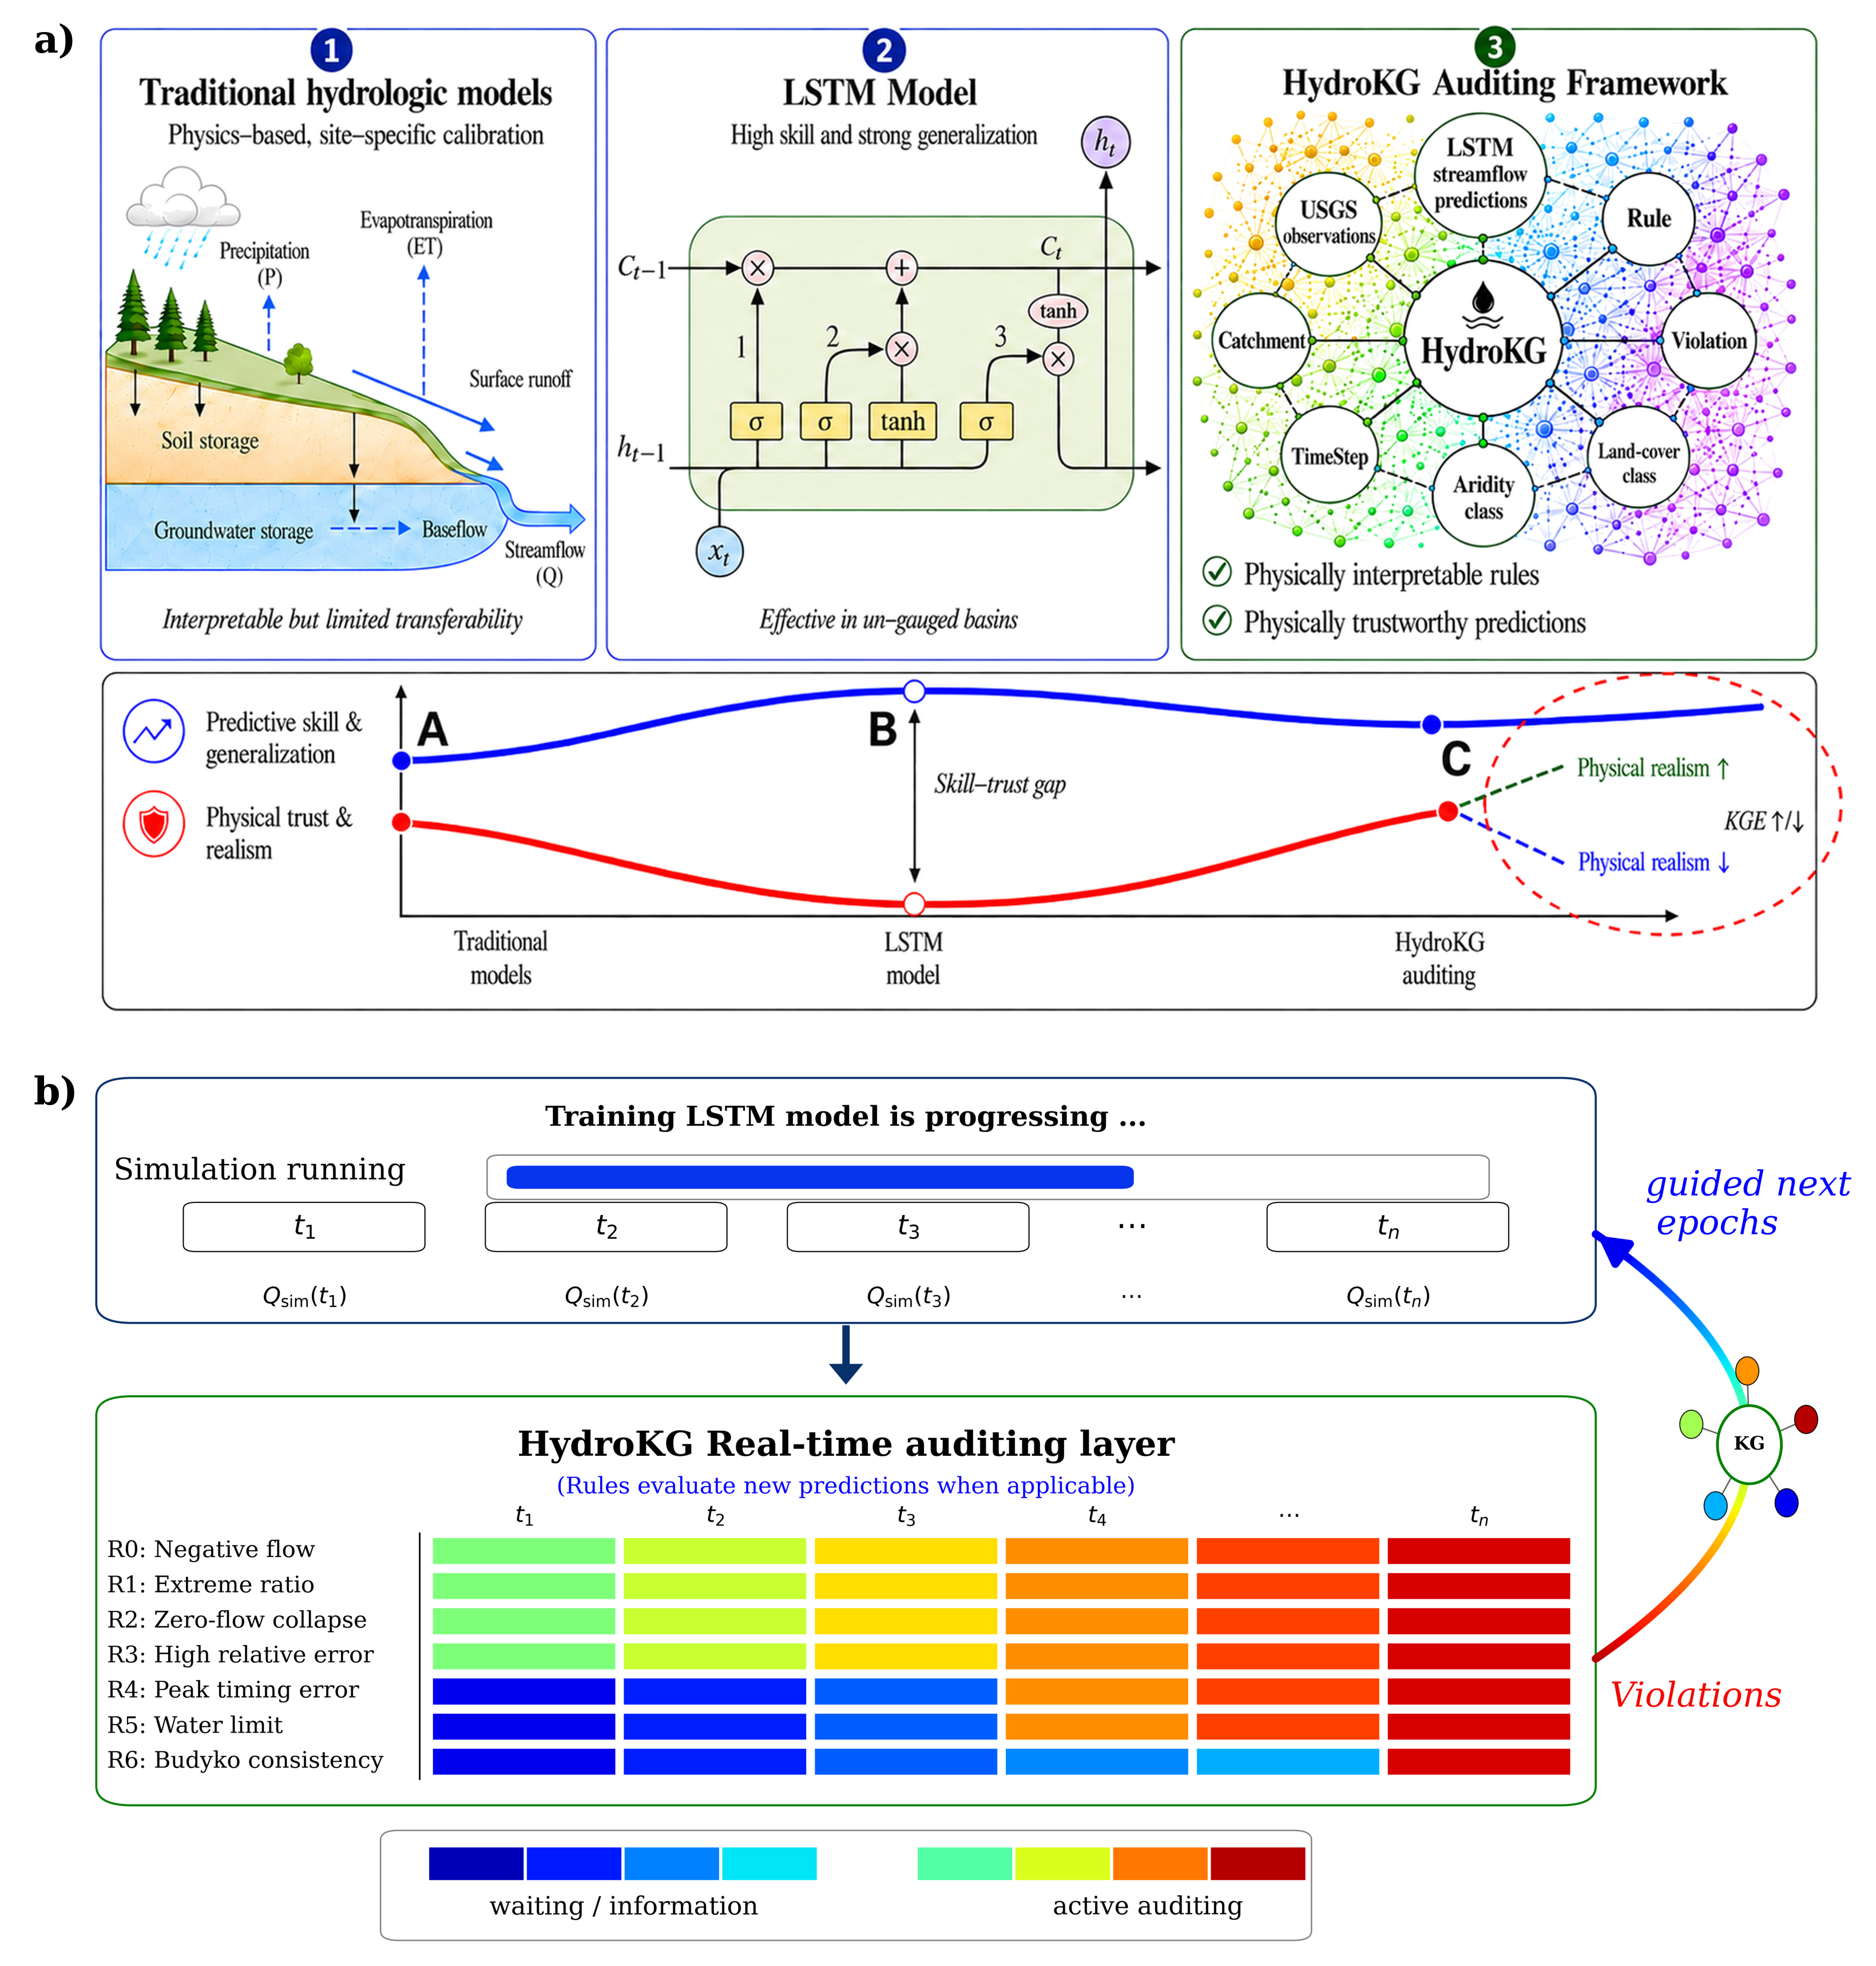

In [1]:
%run /bighome/hdagne1/LSTM-Auditing-HydroKG-v2/Figures/Figure_1.py

Paired basins: 670
Land-cover basins matched to the 6 mapped classes: 669 of 670
Basins with real geometry matched: 670
Spearman rho = -0.49; partial rho given aridity = -0.25; n = 670


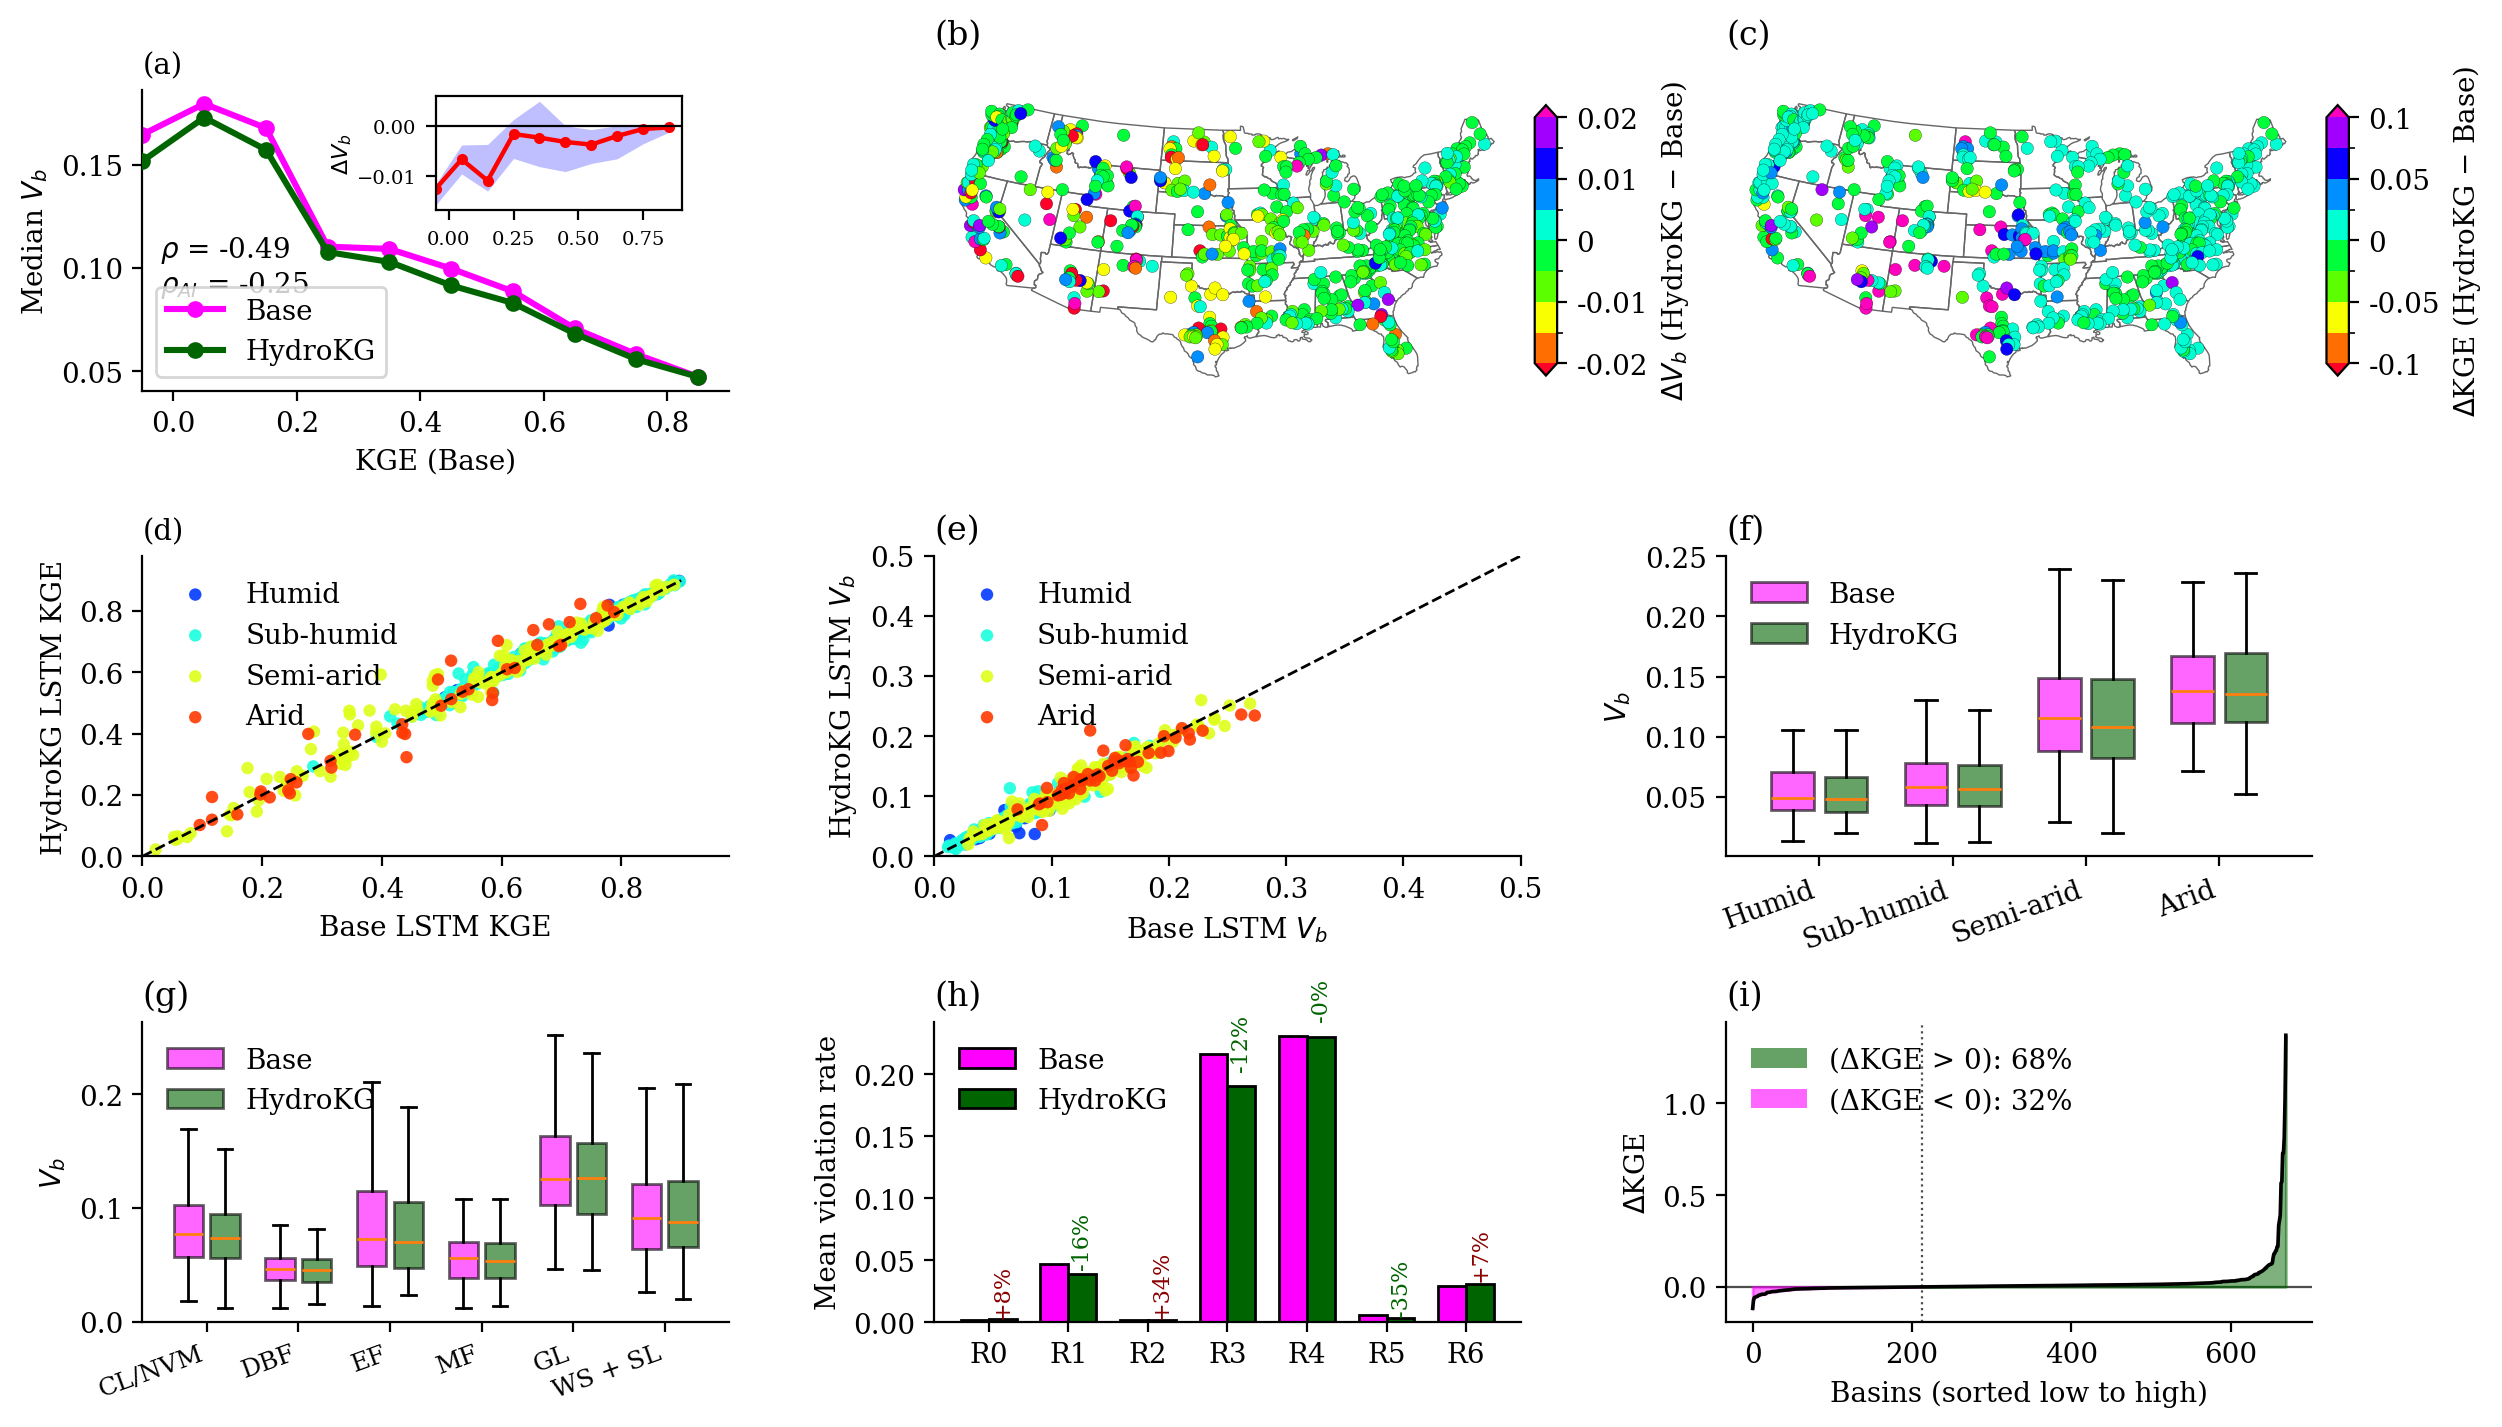

In [2]:
%run /bighome/hdagne1/LSTM-Auditing-HydroKG-v2/Figures/Figure_2.py

Basins per seed: [670]


/bighome/hdagne1/LSTM-Auditing-HydroKG-v2/Figures/Figure_3.py:93: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  quad = D.groupby(["scenario", "seed"]).apply(quadrants).groupby("scenario").mean()



Per scenario (mean over seeds; std in second column):
                   dKGE_median         improved          dV_err         dV_phys            dV_b             dR0             dR1             dR2             dR3             dR4             dR5             dR6        
                         mean     std     mean     std    mean     std    mean     std    mean     std    mean     std    mean     std    mean     std    mean     std    mean     std    mean     std    mean     std
scenario                                                                                                                                                                                                              
HydroKG                0.0023  0.0042  56.5075  9.1943 -0.0066  0.0040 -0.0005  0.0021 -0.0024  0.0019 -0.0014  0.0057 -0.0057  0.0063  0.0002  0.0051 -0.0220  0.0130  0.0008  0.0014 -0.0020  0.0024  0.0020  0.0032
HydroKG (clipped)      0.0023  0.0041  56.6567  9.1372 -0.0078  0.0039 -0.0042  0.00

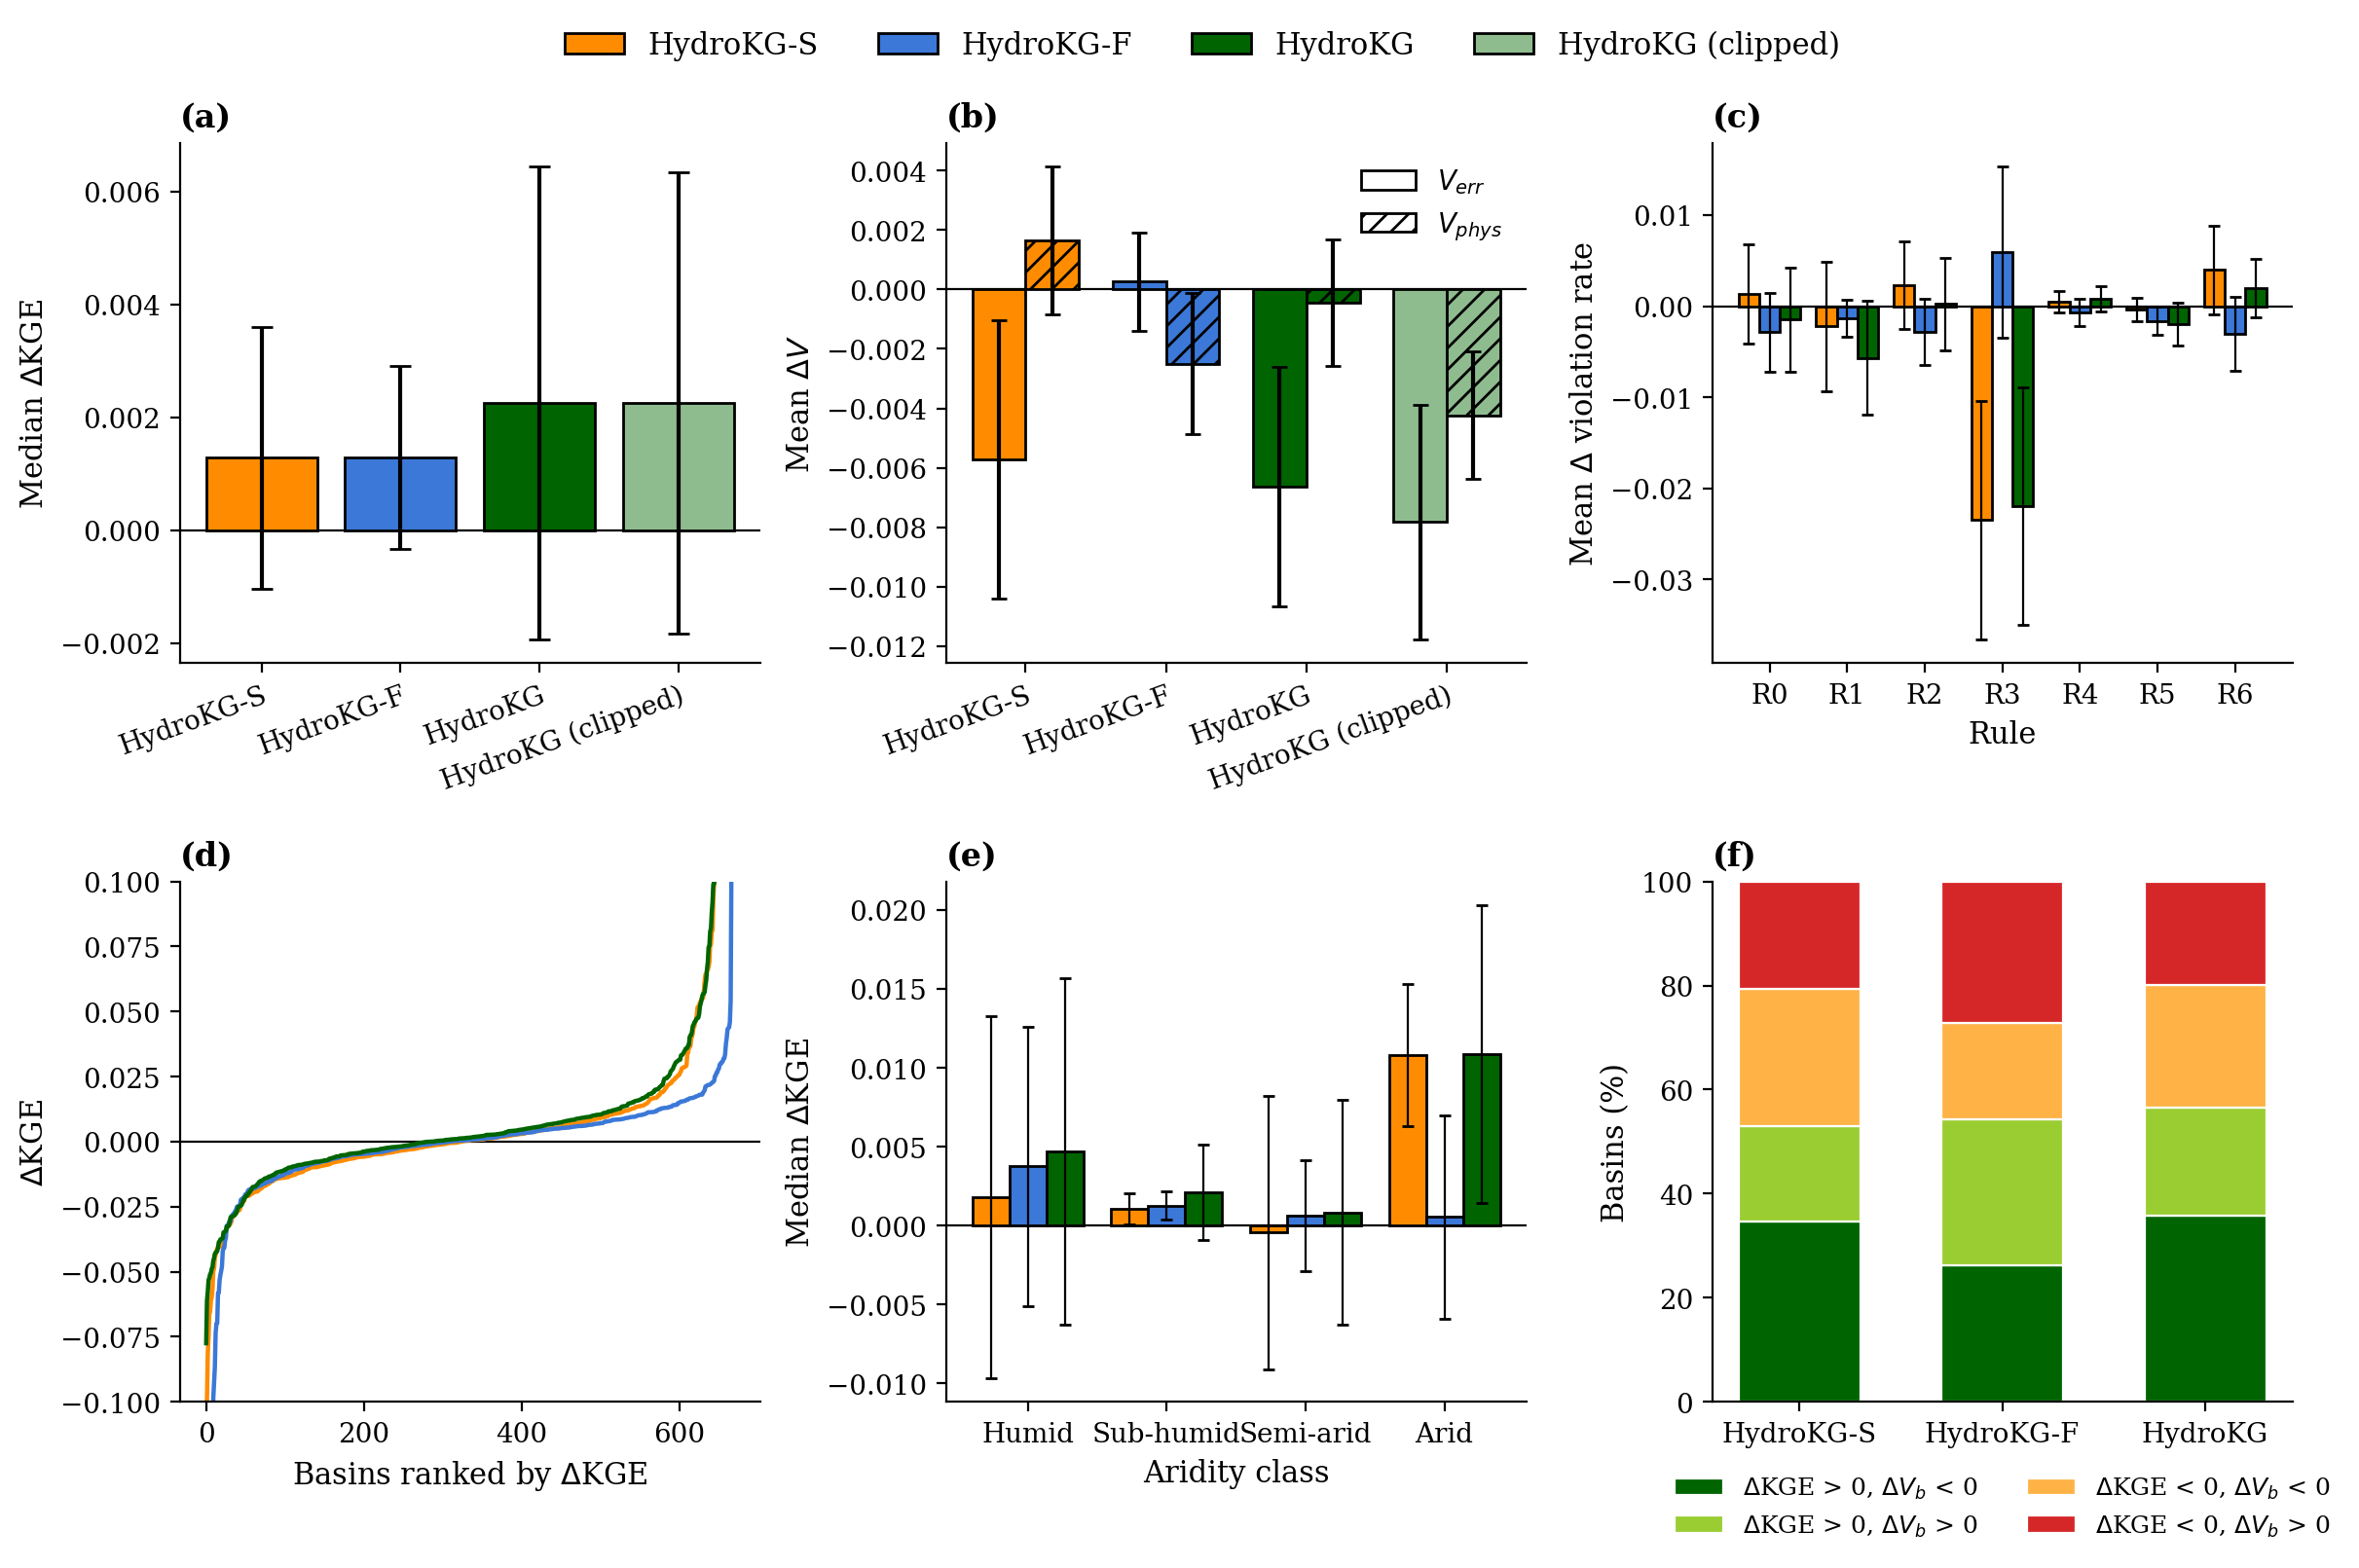

In [3]:
%run /bighome/hdagne1/LSTM-Auditing-HydroKG-v2/Figures/Figure_3.py

Median change by quintile of training-period violation rate (mean, std over seeds):
                 dKGE            dV_b        
                mean     std    mean     std
experiment q                                
HydroKG    1 -0.0003  0.0041  0.0000  0.0001
           2  0.0000  0.0042  0.0002  0.0012
           3  0.0001  0.0032 -0.0006  0.0012
           4  0.0031  0.0078 -0.0020  0.0012
           5  0.0227  0.0193 -0.0080  0.0031
HydroKG-F  1  0.0037  0.0047  0.0001  0.0001
           2  0.0017  0.0013  0.0005  0.0005
           3  0.0013  0.0012  0.0009  0.0010
           4  0.0004  0.0029  0.0005  0.0013
           5  0.0002  0.0058 -0.0020  0.0017
HydroKG-S  1 -0.0012  0.0024  0.0000  0.0001
           2 -0.0017  0.0016  0.0003  0.0013
           3  0.0007  0.0025 -0.0011  0.0007
           4  0.0025  0.0075 -0.0021  0.0010
           5  0.0169  0.0148 -0.0060  0.0040

KGE components (median change):
                  r           alpha            beta        
            

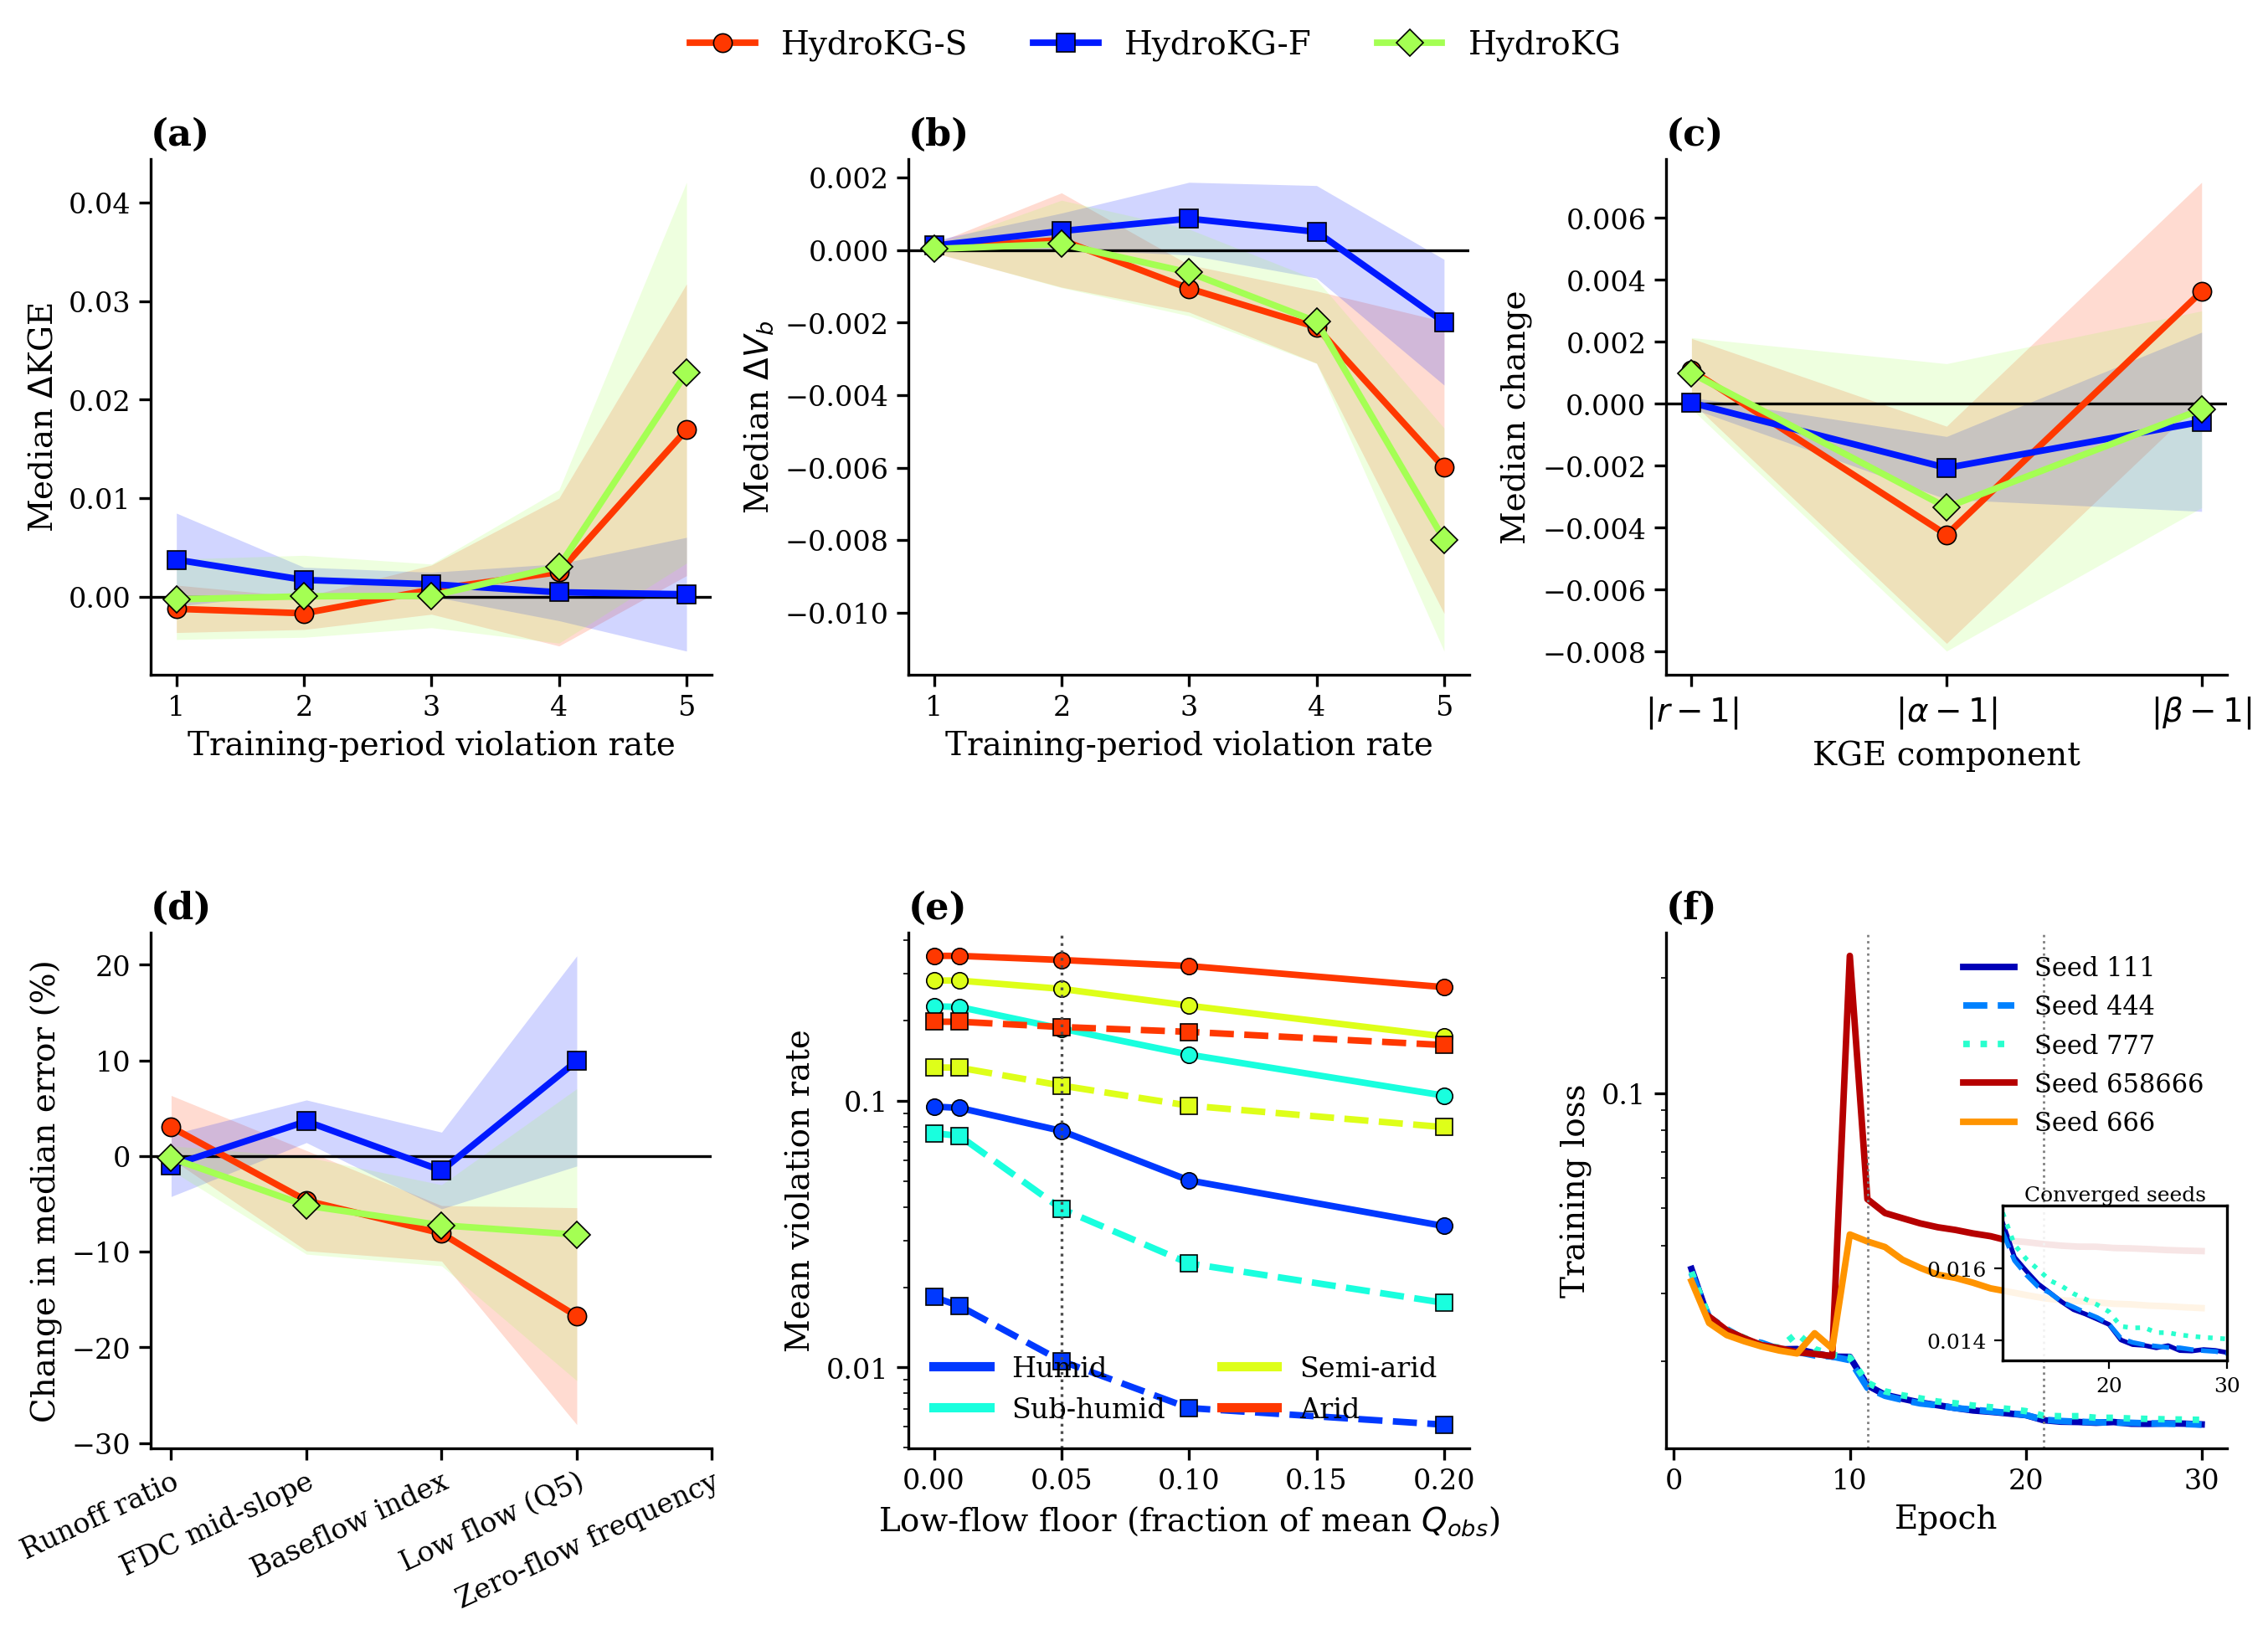

In [4]:
%run /bighome/hdagne1/LSTM-Auditing-HydroKG-v2/Figures/Figure_4.py